# 💳 Credit Card Fraud Detection (without scale_)pos_eight

### Dataset: [MLG-ULB / Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

**Pipeline overview:**
1. Install & import libraries
2. Load & explore the data (EDA)
3. Preprocess (scale + handle imbalance with SMOTE)
4. Train XGBoost model
5. Tune decision threshold
6. Evaluate (AUPRC, Recall, Confusion Matrix)

> ⚠️ Download `creditcard.csv` from Kaggle and place it in the same folder as this notebook.


In [1]:
# Run this cell once to install required packages
# !pip install xgboost imbalanced-learn scikit-learn pandas numpy matplotlib seaborn --quiet

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_curve, auc, average_precision_score
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully ✓")


All libraries imported successfully ✓


## 1. Load & Explore the Data

In [3]:
df = pd.read_csv('creditcard.csv')

# Drop rows where Class is NaN (blank rows at end of CSV)
df = df.dropna(subset=['Class'])
df['Class'] = df['Class'].astype(int)

print(f"Shape: {df.shape}")
print(f"\nClass distribution:")
print(df['Class'].value_counts())
print(f"\nFraud percentage: {df['Class'].mean() * 100:.4f}%")

df.head()


Shape: (284807, 31)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.1727%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


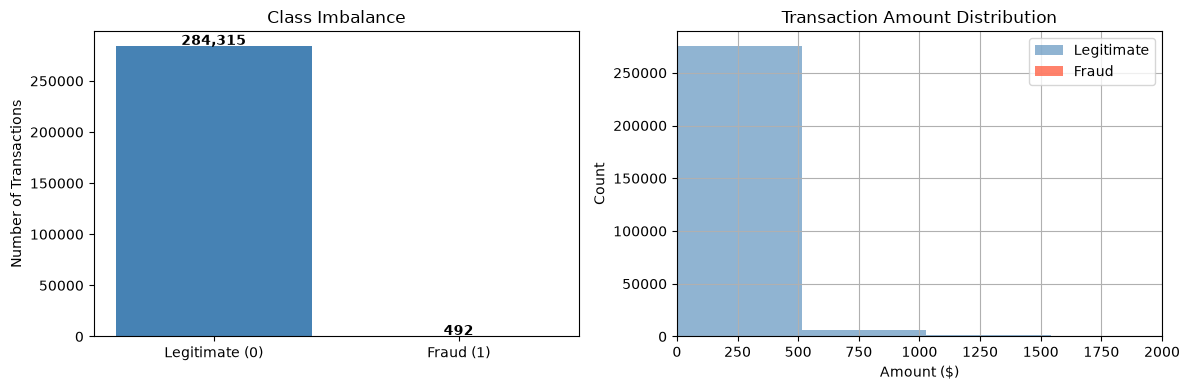


Fraud transaction amount stats:
count     492.00
mean      122.21
std       256.68
min         0.00
25%         1.00
50%         9.25
75%       105.89
max      2125.87
Name: Amount, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class imbalance bar chart
class_counts = df['Class'].value_counts()
axes[0].bar(['Legitimate (0)', 'Fraud (1)'], class_counts.values, color=['steelblue', 'tomato'])
axes[0].set_title('Class Imbalance')
axes[0].set_ylabel('Number of Transactions')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

# Transaction amount distribution by class
df[df['Class'] == 0]['Amount'].hist(ax=axes[1], bins=50, alpha=0.6, label='Legitimate', color='steelblue')
df[df['Class'] == 1]['Amount'].hist(ax=axes[1], bins=50, alpha=0.8, label='Fraud', color='tomato')
axes[1].set_title('Transaction Amount Distribution')
axes[1].set_xlabel('Amount ($)')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].set_xlim(0, 2000)

plt.tight_layout()
plt.show()

print("\nFraud transaction amount stats:")
print(df[df['Class'] == 1]['Amount'].describe().round(2))


## 2. Preprocessing

In [5]:
# Scale Amount and Time (V1-V28 are already PCA-scaled)
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled']   = scaler.fit_transform(df[['Time']])

# Drop original unscaled columns
df_clean = df.drop(columns=['Amount', 'Time'])

# Features and target
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

print(f"Features shape: {X.shape}")
print(f"Target shape:   {y.shape}")


Features shape: (284807, 30)
Target shape:   (284807,)


In [6]:
# Stratified split -- keeps fraud ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train size: {X_train.shape[0]:,}  |  Test size: {X_test.shape[0]:,}")
print(f"Train fraud count: {y_train.sum()}  |  Test fraud count: {y_test.sum()}")

# Apply SMOTE ONLY to training data
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print(f"\nAfter SMOTE -- Train size: {X_train_res.shape[0]:,}")
print(f"Class distribution after SMOTE:\n{pd.Series(y_train_res).value_counts()}")


Train size: 227,845  |  Test size: 56,962
Train fraud count: 394  |  Test fraud count: 98

After SMOTE -- Train size: 454,902
Class distribution after SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


## 3. Train XGBoost Model

In [7]:
# scale_pos_weight tells XGBoost how imbalanced the dataset is
# Formula: majority class count / minority class count
model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    eval_metric='aucpr',       # Area Under Precision-Recall Curve
    use_label_encoder=False,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train_res, y_train_res,
    eval_set=[(X_test, y_test)],
    verbose=False
)

print("Model trained ✓")


Model trained ✓


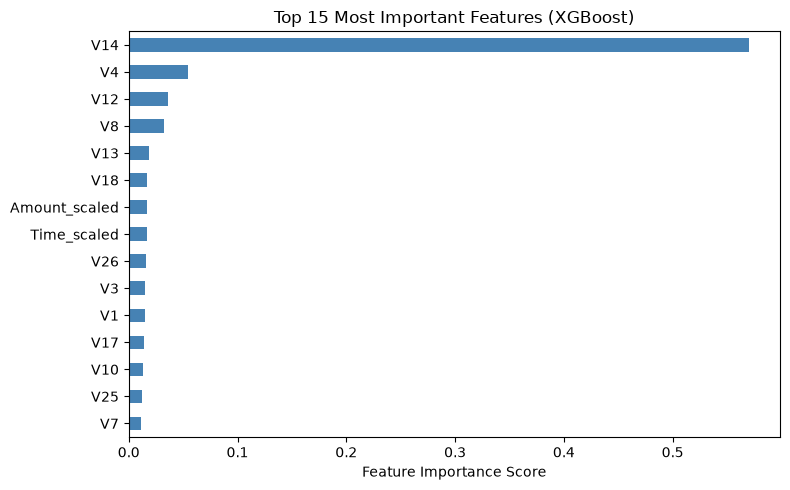

In [8]:
importances = pd.Series(model.feature_importances_, index=X.columns)
top15 = importances.nlargest(15)

plt.figure(figsize=(8, 5))
top15.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 15 Most Important Features (XGBoost)')
plt.xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()


## 4. Evaluate at Default Threshold (0.5)

In [9]:
y_proba = model.predict_proba(X_test)[:, 1]
y_pred  = model.predict(X_test)

print("Classification Report (threshold = 0.5):")
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

# AUPRC
auprc = average_precision_score(y_test, y_proba)
print(f"AUPRC (Area Under Precision-Recall Curve): {auprc:.4f}")


Classification Report (threshold = 0.5):
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.53      0.87      0.66        98

    accuracy                           1.00     56962
   macro avg       0.77      0.93      0.83     56962
weighted avg       1.00      1.00      1.00     56962

AUPRC (Area Under Precision-Recall Curve): 0.8562


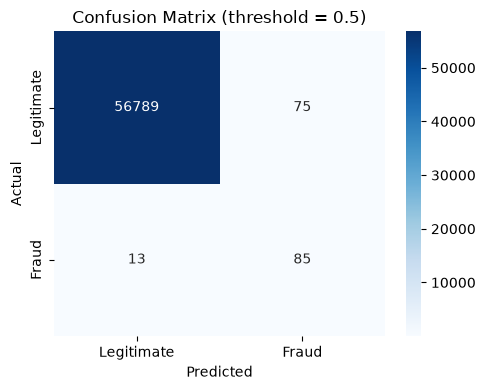

True Positives  (fraud caught):   85
False Negatives (fraud missed):   13
False Positives (false alarms):   75
True Negatives  (legit correct):  56789


In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Fraud'],
            yticklabels=['Legitimate', 'Fraud'])
plt.title('Confusion Matrix (threshold = 0.5)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Positives  (fraud caught):   {tp}")
print(f"False Negatives (fraud missed):   {fn}")
print(f"False Positives (false alarms):   {fp}")
print(f"True Negatives  (legit correct):  {tn}")


## 5. Threshold Tuning via Precision-Recall Curve

Best threshold (max F1): 0.9449
  Precision: 0.9000
  Recall:    0.8265
  F1:        0.8617


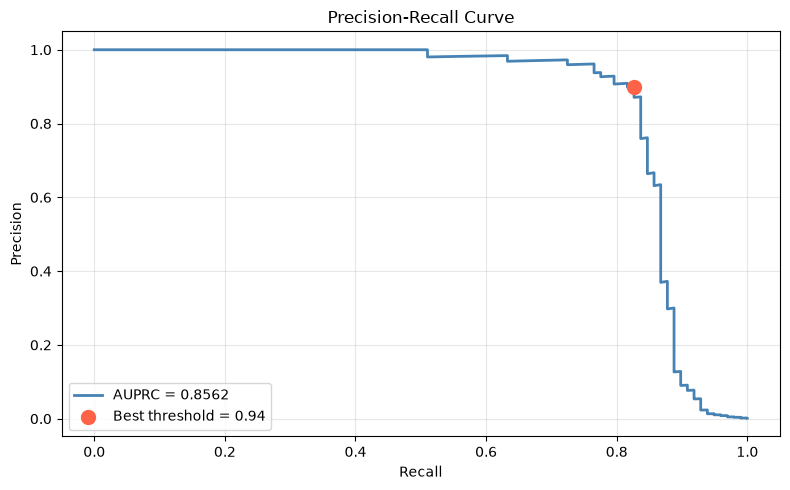

In [11]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

# Find threshold that maximizes F1
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx   = f1_scores.argmax()
best_thresh = thresholds[best_idx]

print(f"Best threshold (max F1): {best_thresh:.4f}")
print(f"  Precision: {precision[best_idx]:.4f}")
print(f"  Recall:    {recall[best_idx]:.4f}")
print(f"  F1:        {f1_scores[best_idx]:.4f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, color='steelblue', lw=2, label=f'AUPRC = {auprc:.4f}')
plt.scatter(recall[best_idx], precision[best_idx],
            color='tomato', zorder=5, s=100,
            label=f'Best threshold = {best_thresh:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Classification Report (threshold = 0.9449):
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.90      0.83      0.86        98

    accuracy                           1.00     56962
   macro avg       0.95      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962



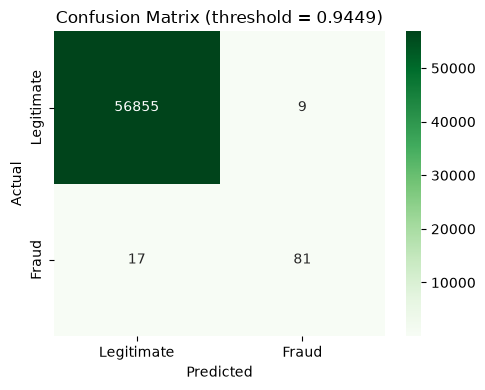

In [12]:
y_pred_tuned = (y_proba >= best_thresh).astype(int)

print(f"Classification Report (threshold = {best_thresh:.4f}):")
print(classification_report(y_test, y_pred_tuned, target_names=['Legitimate', 'Fraud']))

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Legitimate', 'Fraud'],
            yticklabels=['Legitimate', 'Fraud'])
plt.title(f'Confusion Matrix (threshold = {best_thresh:.4f})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()


## Summary

| Step | Choice | Reason |
|---|---|---|
| Imbalance handling | SMOTE on train only | Synthesizes minority samples without data leakage |
| Algorithm | XGBoost | Strong on tabular data, native imbalance support |
| Primary metric | AUPRC | Accuracy is misleading on imbalanced data |
| Threshold | Tuned via P-R curve | Default 0.5 is not optimal for rare fraud class |

**Next steps to try:**
- Cross-validation with `StratifiedKFold`
- Hyperparameter tuning with `Optuna` or `GridSearchCV`
- Compare with `IsolationForest` (unsupervised anomaly detection)
- Add SHAP values for model explainability
